# Tugas 2 — Deteksi Transaksi *Fraud* (Klasifikasi Biner)

Notebook ini menjalankan pipeline Tugas 2 langkah demi langkah dengan kode yang sama seperti
`python kode/run_all.py --stages klasifikasi`. Setiap butir menjalankan modulnya di
`kode/src/klasifikasi/`, lalu menampilkan ringkasan angka dari `kode/results/` dan grafik dari
`kode/figures/`.

| Butir | Isi | Modul | Penanggung jawab |
| --- | --- | --- | --- |
| 2a | Audit label dan fitur serta pengukuran dampaknya | `audit.py`, `audit_dampak.py` | Firdaus Arif Ramadhani |
| 2b | Validasi berbasis waktu yang tahan *right-censoring* | `validation.py` | Firdaus Arif Ramadhani |
| 2c | Fitur perilaku kausal pengguna dan *merchant* | `features.py` | Rainaldi Pakpahan |
| 2d | Penanganan *class imbalance* dan perbandingan model | `models.py` | Rainaldi Pakpahan |
| 2e | Pergeseran pola *fraud* dan adaptasi model | `shift.py` | Rainaldi Pakpahan |
| 2f | Kalibrasi probabilitas dan aturan keputusan berbasis biaya | `calibration.py` | Rainaldi Pakpahan |
| 2g | Analisis *error*, SHAP, dan `prediksi_klasifikasi.csv` | `analysis.py` | Rainaldi Pakpahan |

Metrik penilaian: PR-AUC dari `prob` dan biaya total = jumlah nominal *fraud* yang lolos + Rp25.000 ×
jumlah transaksi yang ditandai. Seluruh langkah memakai `SEED = 42`.

## Persiapan

Sel ini menyiapkan *path*, *seed* global, dan dua pembantu: `baca_hasil()` untuk membaca JSON hasil
dan `tampilkan_gambar()` untuk menampilkan grafik. Data dibaca dari folder `data/` di *root* repositori
(atau dari variabel lingkungan `UTS_ML_DATA_DIR`).

In [1]:
import json
import sys
import warnings
from io import BytesIO
from pathlib import Path

import matplotlib

# Peringatan informatif yang tidak memengaruhi hasil (deprecation pandas, tqdm, format keluaran SHAP)
warnings.filterwarnings("ignore", message="Constructing a Categorical with a dtype")
warnings.filterwarnings("ignore", message="IProgress not found")
warnings.filterwarnings("ignore", message="LightGBM binary classifier with TreeExplainer")

# Backend non-interaktif: grafik disimpan ke kode/figures/ lalu ditampilkan dari berkasnya
matplotlib.use("Agg")

import pandas as pd  # noqa: E402
from IPython.display import Image, Markdown, display  # noqa: E402
from PIL import Image as PILImage  # noqa: E402

# Notebook dijalankan dari kode/notebooks/; folder kode/ dimasukkan ke sys.path
KODE_DIR = Path.cwd().resolve()
if KODE_DIR.name == "notebooks":
    KODE_DIR = KODE_DIR.parent
if str(KODE_DIR) not in sys.path:
    sys.path.insert(0, str(KODE_DIR))

from src.config import FIGURES_DIR, REPO_ROOT, RESULTS_DIR, SEED  # noqa: E402
from src.utils import set_global_seed  # noqa: E402

set_global_seed(SEED)
pd.set_option("display.precision", 4)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)


def baca_hasil(nama: str) -> dict:
    """Baca berkas JSON hasil eksperimen dari kode/results/."""
    return json.loads((RESULTS_DIR / nama).read_text(encoding="utf-8"))


def tampilkan_gambar(nama: str, lebar: int = 1100) -> None:
    """Tampilkan grafik dari kode/figures/ (diperkecil agar notebook tetap ringan)."""
    gambar = PILImage.open(FIGURES_DIR / nama)
    if gambar.width > lebar:
        tinggi = round(gambar.height * lebar / gambar.width)
        gambar = gambar.resize((lebar, tinggi), PILImage.LANCZOS)
    buffer = BytesIO()
    gambar.save(buffer, format="PNG", optimize=True)
    display(Image(data=buffer.getvalue()))


def tabel_metrik(kamus: dict, kolom: list[str] | None = None) -> pd.DataFrame:
    """Ubah {nama: {metrik: nilai}} menjadi tabel (baris = nama, kolom = metrik)."""
    df = pd.DataFrame.from_dict(kamus, orient="index")
    return df[kolom] if kolom else df


print(f"Folder kode : {KODE_DIR.relative_to(REPO_ROOT)}/")
print(f"Seed global : {SEED}")

Folder kode : kode/
Seed global : 42


## 2a. Audit Label dan Fitur

*Penanggung jawab: Firdaus Arif Ramadhani*

Pemeriksaan yang dijalankan `audit.py`:

- **Skema, waktu, dan ID:** dimensi, duplikat, irisan *train*–*test*, urutan baris, keacakan ID.
- **Jeda label (*right-censoring*):** *fraud* baru terkonfirmasi beberapa hari setelah transaksi,
  sehingga label Agustus 2025 belum lengkap pada tanggal penarikan data.
- ***Leakage*:** `flag_review_manual` terjadi sesudah transaksi sehingga tidak boleh dipakai.
- **Kualitas data:** *missing* terstruktur, `umur_merchant_hari < 0`, `persen_saldo` yang terpotong di 50,
  entitas *unseen*.
- ***Screening* `v01`–`v50`:** memisahkan fitur anonim yang bersinyal dari yang *noise*.
- **Pergeseran pola:** gelombang *fraud* QRIS mulai Agustus 2025.
- **Dampak:** empat eksperimen mengukur efek setiap temuan pada split kronologis yang labelnya matang.

In [2]:
%run ../src/klasifikasi/audit.py --save-json

[START] Muat dataset klasifikasi


[DONE]  Muat dataset klasifikasi (1.24s)
[START] 2a.1 Skema & duplikat


  Train=[403077, 85], Test=[106674, 84], dup_id=0
[DONE]  2a.1 Skema & duplikat (0.80s)
[START] 2a.2 Rentang waktu & urutan
  Train terurut=False, Test terurut=False
[DONE]  2a.2 Rentang waktu & urutan (0.08s)
[START] 2a.3 Keacakan ID


  Spearman(id_transaksi, waktu)=0.00034
[DONE]  2a.3 Keacakan ID (0.38s)
[START] 2a.4 Label & kurva delay konfirmasi


  Laju matang Jan–Jul=0.679%, Agt=0.463%, 29–31 Agt fraud=0/4780
[DONE]  2a.4 Label & kurva delay konfirmasi (1.06s)
[START] 2a.5 Audit forensik leakage flag_review_manual


  Review rate train=1.71% (non-fraud=1.20%), test=1.23%
[DONE]  2a.5 Audit forensik leakage flag_review_manual (0.66s)
[START] 2a.6 Kualitas fitur, missing, anomali, & unseen


  umur_merchant<0: n_tr=955 (fraud=20.31%), n_te=20
[DONE]  2a.6 Kualitas fitur, missing, anomali, & unseen (2.40s)
[START] 2a.7 Screening 50 fitur anonim v01–v50


  8 sinyal v=['v03', 'v11', 'v19', 'v26', 'v29', 'v38', 'v42', 'v47']; v15 drift KS=0.502, AUC=0.503
[DONE]  2a.7 Screening 50 fitur anonim v01–v50 (9.61s)
[START] 2a.8 Pergeseran pola fraud & arketipe modus


  QRIS fraud Jan–Jul=0.119% -> Agt=0.789%; QRIS bulat 100rb di Agt fraud=79.3%, di test=461
[DONE]  2a.8 Pergeseran pola fraud & arketipe modus (0.59s)
[START] 2a.9 Eksperimen dampak kuantitatif (4 temuan)


  PR-AUC bocor CV=0.9017 -> simulasi uji=0.6889 vs jujur=0.7656
[DONE]  2a.9 Eksperimen dampak kuantitatif (4 temuan) (67.47s)
[SAVED] task2_audit.json


In [3]:
audit = baca_hasil("task2_audit.json")
label = audit["label_delay"]
display(Markdown("**Laju fraud (%) menurut kematangan label**"))
display(pd.Series({
    "Seluruh train": label["laju_fraud_total_pct"],
    "Jan–Jul (label matang)": label["laju_fraud_matang_pct"],
    "Agustus (tersensor)": label["laju_fraud_agustus_pct"],
}, name="laju_fraud_pct").to_frame())

kolom = ["pr_auc", "roc_auc", "ratio_pred_to_obs", "flag_rate_pct", "total_cost_idr"]
baris = {}
for eksperimen, isi in audit["dampak"].items():
    if not isinstance(isi, dict) or eksperimen == "split_info":
        continue
    for varian, metrik in isi.items():
        if isinstance(metrik, dict) and "pr_auc" in metrik:
            baris[(eksperimen, varian)] = {k: metrik.get(k) for k in kolom}
display(Markdown("**Eksperimen dampak (split kronologis matang)**"))
display(pd.DataFrame.from_dict(baris, orient="index"))

**Laju fraud (%) menurut kematangan label**

,laju_fraud_pct
Seluruh train,0.6505
Jan–Jul (label matang),0.6788
Agustus (tersensor),0.4631


**Eksperimen dampak (split kronologis matang)**

pr_auc  roc_auc  ratio_pred_to_obs  flag_rate_pct  total_cost_idr
indikator_kualitas    matang_jun_jul_dasar             0.7656   0.9873             0.9466         1.0953      7.4257e+07
                      matang_jun_jul_dengan_flag       0.7645   0.9877             0.9456         1.1323      7.4609e+07
                      qris_shift_agt11_21_dasar        0.5227   0.9865             0.7536         1.7300      8.7048e+06
                      qris_shift_agt11_21_dengan_flag  0.5733   0.9907             0.9438         1.8275      4.0054e+06
label_delay_censoring val_agt_akhir_15_31              0.1247   0.9254             2.2541         1.0910      3.8168e+07
                      val_agt_akhir_non_qris           0.1786   0.9852             3.7430         1.2207      8.3786e+06
                      val_agt_penuh_tersensor          0.2747   0.9251             1.3453         1.2041      1.1865e+08
                      val_jul_matang                   0.7830   0.9870             0.9977         1.2497      3.6901e+07
leakage_review_manual dengan_review_cv_naif            0.9017   0.9956             0.9615         0.8023      3.6775e+07
                      dengan_review_simulasi_uji       0.6889   0.9825             0.6850         0.6806      9.7322e+07
                      jujur_tanpa_review               0.7656   0.9873             0.9466         1.0953      7.4257e+07
seleksi_fitur_v       bernama_plus_8_v_sinyal          0.7656   0.9873             0.9466         1.0953      7.4257e+07
                      hanya_bernama_tanpa_v            0.7607   0.9862             0.9713         1.2414      7.7586e+07
                      semua_50_v                       0.7566   0.9856             0.9185         1.0671      7.6476e+07

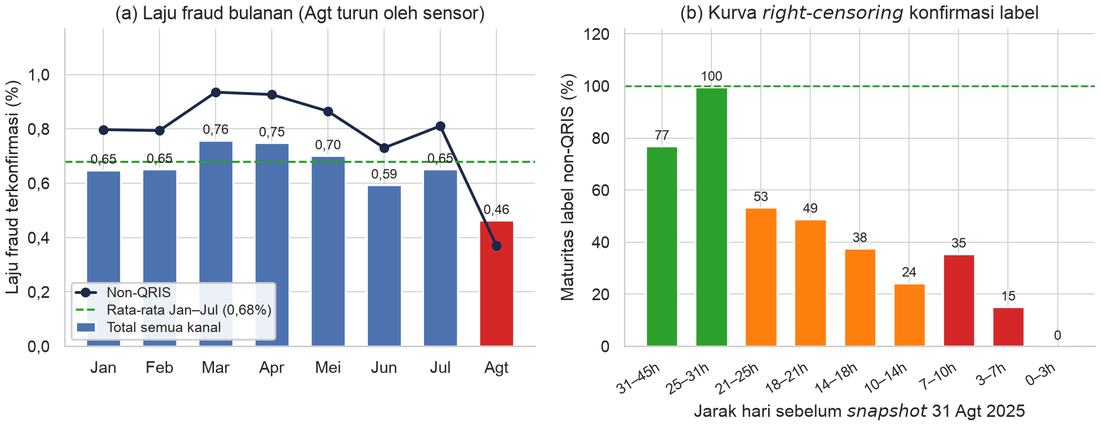

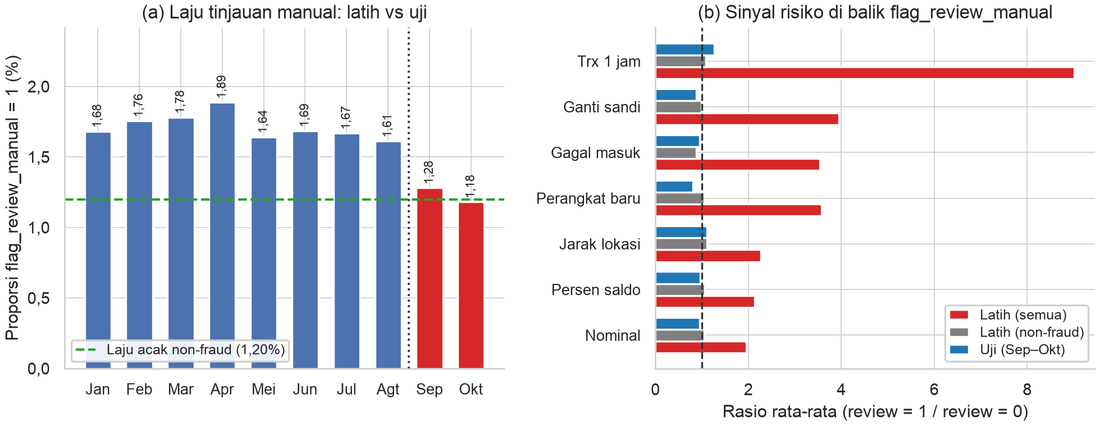

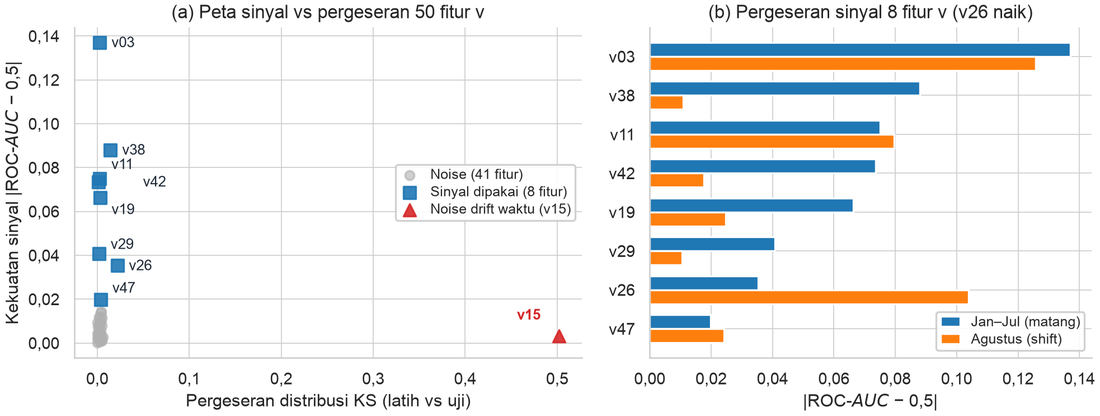

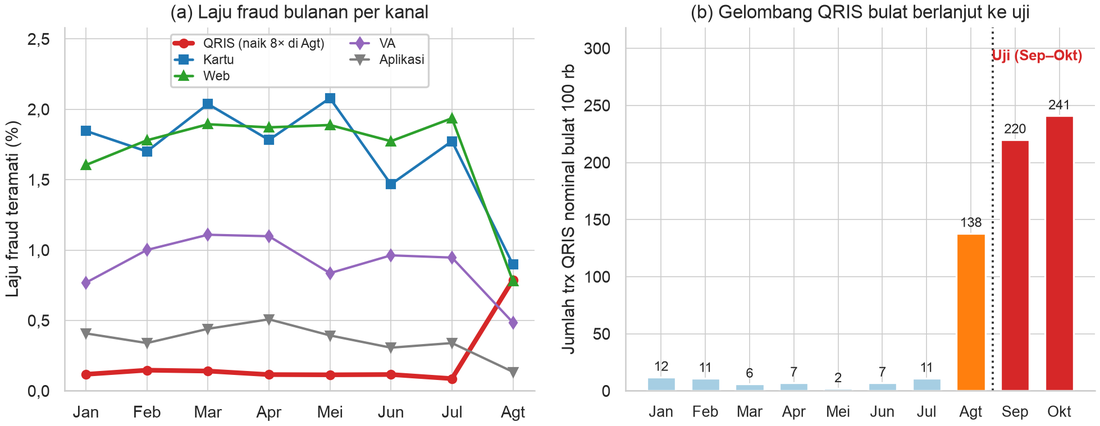

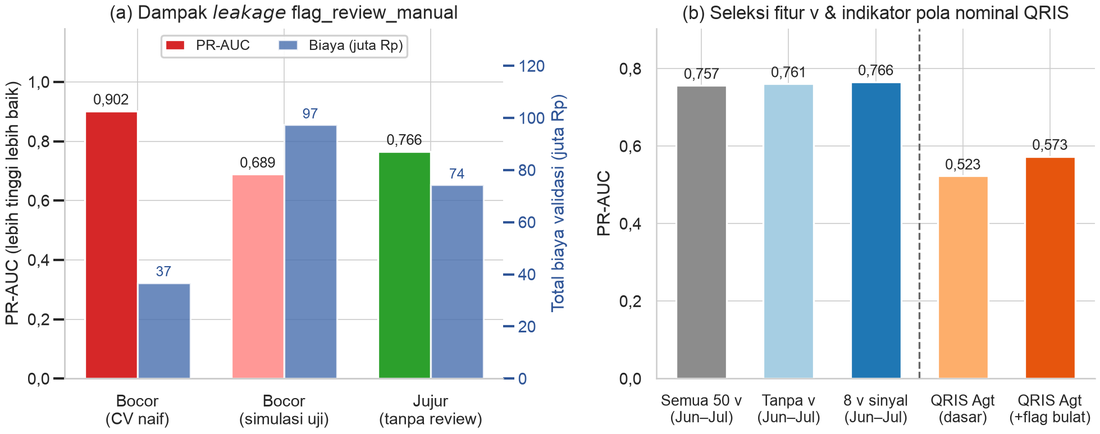

In [4]:
for nama in (
    "task2_2a1_label_delay.png",
    "task2_2a2_leakage_review.png",
    "task2_2a3_v_screening.png",
    "task2_2a4_pattern_shift.png",
    "task2_2a5_dampak_audit.png",
):
    tampilkan_gambar(nama)